In [175]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple
from jaxopt import AndersonAcceleration
import pickle
import os
import optax
from scipy import stats
from scipy.optimize import curve_fit
import pandas as pd
import seaborn as sns
from tqdm import trange
from itertools import product
import openpyxl
from sklearn.cluster import KMeans
from scipy.optimize import linear_sum_assignment




## 1. Naka–Rushton 

Fixing Hill exponents from Elisa

In [176]:
# Naka-Rushton function

def nr(x, n):
    """Naka-Rushton activation function"""
    x = jnp.maximum(x, 0.0)
    return jnp.power(x, n) / (jnp.power(x, n) + 1)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


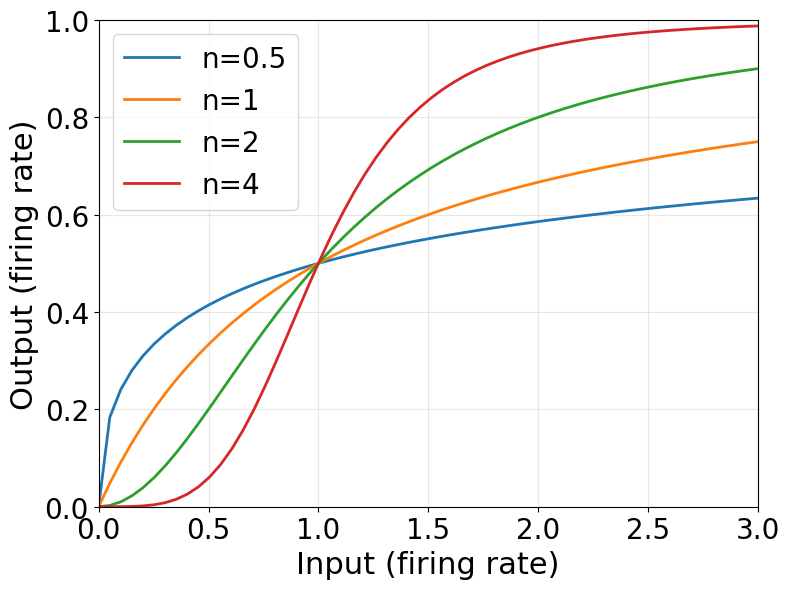

In [177]:
# Visualise the Naka-Rushton function
x_vals = jnp.linspace(0, 5, 100)
n_values = [0.5, 1, 2, 4]

plt.figure(figsize=(8, 6))
for n in n_values:
    y_vals = nr(x_vals, n=n)
    plt.plot(x_vals, y_vals, label=f'n={n}', linewidth=2)

plt.xlabel('Input (firing rate)', fontsize=22)
plt.ylabel('Output (firing rate)', fontsize=22)
plt.grid(True, alpha=0.3)
plt.xlim(0, 3)
plt.ylim(0, 1)
plt.tick_params(axis='both', direction='out', labelsize=20)
plt.legend(fontsize=20)
plt.tight_layout()
plt.savefig(f'Figures_final/naka_rushton_og.eps')
plt.show()

In [178]:
n_r = 1.850
n_g = 1.868
n_b = 0.642
n_y = 1.562

## 2. Symmetric weight



In [179]:

def unpack_theta(theta, m):
    w_osn_r = jnp.array([theta[0], theta[0]])
    w_osn_b = jnp.array([theta[1], theta[1]])
    w_osn_g = jnp.array([theta[2], theta[2]])
    w_osn_y = jnp.array([theta[3], theta[3]])
    w_b_r = jnp.array([theta[4], theta[4]])
    w_b_g = jnp.array([theta[5], theta[5]])
    w_b_y = jnp.array([theta[6], theta[6]])
    w_r_y = jnp.array([theta[7], theta[7]])
    w_r_g = jnp.array([theta[8], theta[8]])
    alpha = jnp.array([theta[9], theta[9]])
    # Build 2x2 matrices so all elements are same type (avoids JAX shape error)
    zero = jnp.asarray(0.0)
    wr = jnp.asarray(theta[10])
    wy = jnp.asarray(theta[11])
    W_g_r = jnp.stack([jnp.stack([zero, wr]), jnp.stack([wr, zero])])
    W_g_y = jnp.stack([jnp.stack([zero, wy]), jnp.stack([wy, zero])])
    y_max_g = theta[12]
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, y_max_g


# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g, y_max_g):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g) * y_max_g

    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r, n_b, n_g):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, y_max_g = unpack_theta(theta, m)
    g0 = jnp.zeros(m)

    # Pass y_max_g as explicit arg so JAX can differentiate w.r.t. it (closed-over values break custom_vjp)
    def fixed_point_with_y_max(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, y_max_g):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g, y_max_g)

    aa = AndersonAcceleration(fixed_point_with_y_max, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, y_max_g)
    return solution.params

# Compute mitral output with different n values
def mitral_output(theta, x, m, n_r, n_b, n_g, n_y):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, y_max_g = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m, n_r, n_b, n_g)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)

    return r, g, b, y

## 3. Random initialisations and Adam optimisation to hit output targets

- draw many initial `theta`
- minimise a squared-error loss on target firing rates
- keep converged solutions

In [180]:
# set up optimisation problem
m = 2  # number of mitral neurons
n_var = 4  # r, g, b, y
n = n_var * m  # total state length
x = jnp.ones(m)  # input odour signal

# Naka-Rushton n values for each neuron type
n_r = 1.850
n_g = 1.868
n_b = 0.642
n_y = 1.562

# target firing rates (all neurons should fire around 0.5)
y_target = jnp.array([0.5, 0.5])  # mitral cell output
g_target = jnp.array([0.5, 0.5])  # green neurons
b_target = jnp.array([0.5, 0.5])  # blue neurons
r_target = jnp.array([0.5, 0.5])  # red neurons

# number of parameters in the model
# parameters: w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g,
#            alpha, W_g_r, W_g_y, y_max_g
no_params = 13  # total number of parameters

print(f"Setup:")
print(f"  - Number of mitral neurons (channels): {m}")
print(f"  - Number of parameters: {no_params}")
print(f"  - Target firing rates: {np.array(y_target)}")
print(f"  - Input signal: {np.array(x)}")
print(f"  - N values: n_r={n_r}, n_b={n_b}, n_g={n_g}, n_y={n_y}")

Setup:
  - Number of mitral neurons (channels): 2
  - Number of parameters: 13
  - Target firing rates: [0.5 0.5]
  - Input signal: [1. 1.]
  - N values: n_r=1.85, n_b=0.642, n_g=1.868, n_y=1.562


## 4. Load params, test stability 



In [181]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_562_zz.pkl'
with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count 
print(f"Loaded theta_opt shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

Loaded theta_opt shape: (562, 13)
Number of samples: 562
Number of parameters per sample: 13


All stable, therefore can just use theta_opt

## 5. Hessian 


Processing 562 samples...
  Sample 1/562...
  Sample 101/562...
  Sample 201/562...
  Sample 301/562...
  Sample 401/562...
  Sample 501/562...
Completed processing 562 samples


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


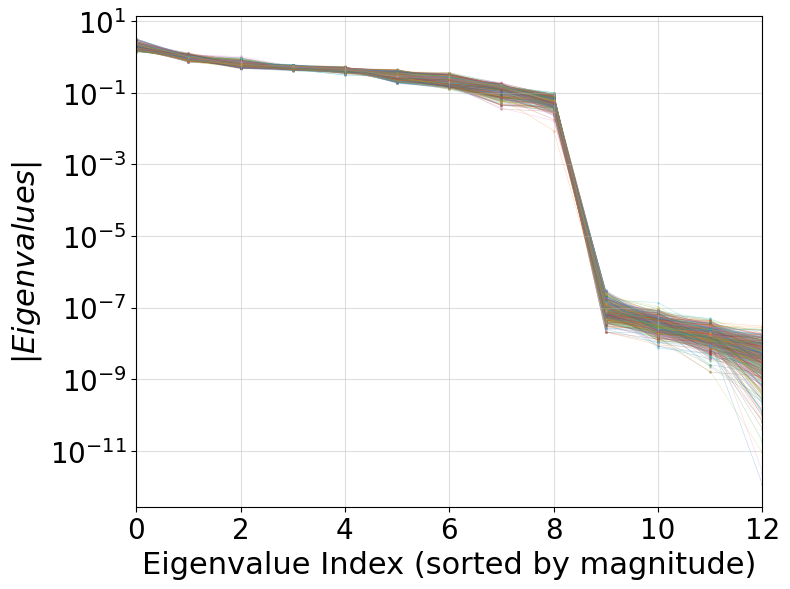

In [182]:
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m, n_r, n_b, n_g, n_y)
    return jnp.sum(y)

grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

theta_samples = theta_opt

print(f"Processing {theta_samples.shape[0]} samples...")
n_samples, n_params = theta_samples.shape[0], theta_samples.shape[1]
all_eigenvalues = np.zeros((n_samples, n_params))
all_eigenvectors = np.zeros((n_samples, n_params, n_params))

# Process all samples
for i in range(n_samples):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")

    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))

    # Compute and sort eigenvalues in one step
    eigenvalues_H = np.array(jnp.linalg.eigh(H).eigenvalues)
    eigenvectors_H = np.array(jnp.linalg.eigh(H).eigenvectors)
    all_eigenvalues[i, :] = np.abs(eigenvalues_H[np.argsort(np.abs(eigenvalues_H))[::-1]])
    all_eigenvectors[i, :, :] = eigenvectors_H[:, np.argsort(np.abs(eigenvalues_H))[::-1]]

print(f"Completed processing {n_samples} samples")

# Visualise
fig, ax = plt.subplots(figsize=(8, 6))
n_params = all_eigenvalues.shape[1]

# Plot individual samples (one colour per sample)
x_idx = np.arange(n_params)
for i in range(n_samples):
    ax.semilogy(x_idx, all_eigenvalues[i, :], 'o-', ms=1, lw=0.4, alpha=0.3, zorder=1)

# Plot statistics
ax.set_xlabel('Eigenvalue Index (sorted by magnitude)', fontsize=22)
ax.set_ylabel('$|Eigenvalues|$', fontsize=22)
ax.set_xlim(0, n_params-1)
ax.tick_params(axis='both', labelsize=20, direction='out')
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig('Figures_z/hessian_eigenvalues.eps')
plt.show()

================================

# s perp

In [183]:
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m, n_r, n_b, n_g, n_y)
    return jnp.sum(y)

idx_ymax = 12  # y_max_g is the 13th parameter (index 12)

grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

n_samples, n_params = theta_samples.shape[0], theta_samples.shape[1]

v = jnp.zeros(n_params)
v = v.at[idx_ymax].set(-1)  # y_max_g is the parameter being changed

x_collect = []
for i in range(n_samples):
#for i in range(3):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")

    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))

    H1 = (jnp.eye(n_params) - v[:, None] * v[None, :]) @ H @ (jnp.eye(n_params) - v[:, None] * v[None, :])
    h2 = (jnp.eye(n_params) - v[:, None] * v[None, :]) @ H @ v

    s_perp = -jnp.linalg.pinv(H1, rtol=1e-6) @ h2 # pseudo inverse

    x_collect.append(s_perp + v)

x_collect = jnp.array(x_collect)




  Sample 1/562...
  Sample 101/562...
  Sample 201/562...
  Sample 301/562...
  Sample 401/562...
  Sample 501/562...


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


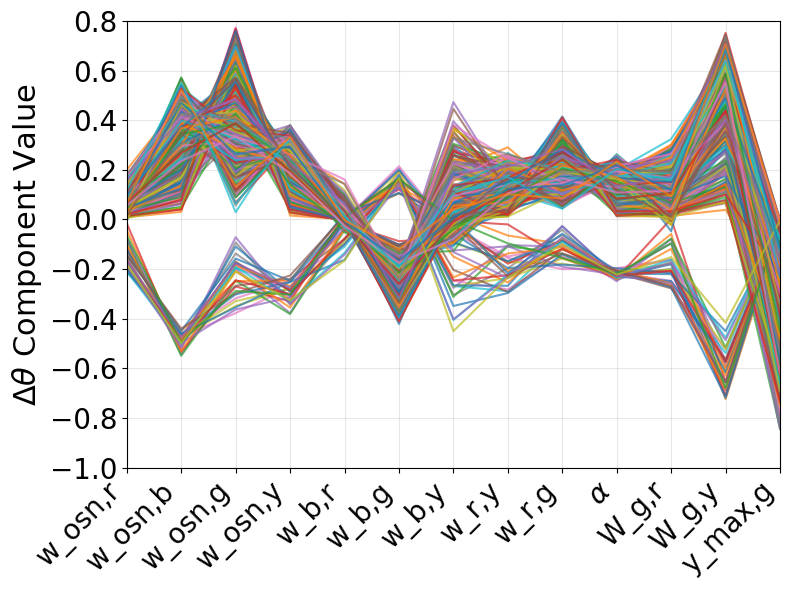

In [184]:
#plot all x_collect, each row is a different colour

x_collect = x_collect / jnp.linalg.norm(x_collect, axis=1, keepdims=True)

param_labels = [
    'w_osn,r', 'w_osn,b', 'w_osn,g', 'w_osn,y',
    'w_b,r', 'w_b,g', 'w_b,y', 'w_r,y', 'w_r,g',
    r"$\alpha$", 'W_g,r', 'W_g,y', 'y_max,g',
]

x_collect_np = np.array(x_collect)
indices = np.arange(len(param_labels))

plt.figure(figsize=(8, 6))
for row_idx in range(x_collect_np.shape[0]):
    plt.plot(indices, x_collect_np[row_idx], alpha=0.7)

plt.ylabel(r"$\Delta\theta$ Component Value", fontsize=22)
plt.xlim(0, 12)
plt.ylim(-1, 0.8)
plt.xticks(range(len(param_labels)), param_labels, rotation=45, ha='right', fontsize=20)
plt.yticks(fontsize=20)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'Figures_z/x_collect_all.eps')
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


382 / 562 vectors match filter


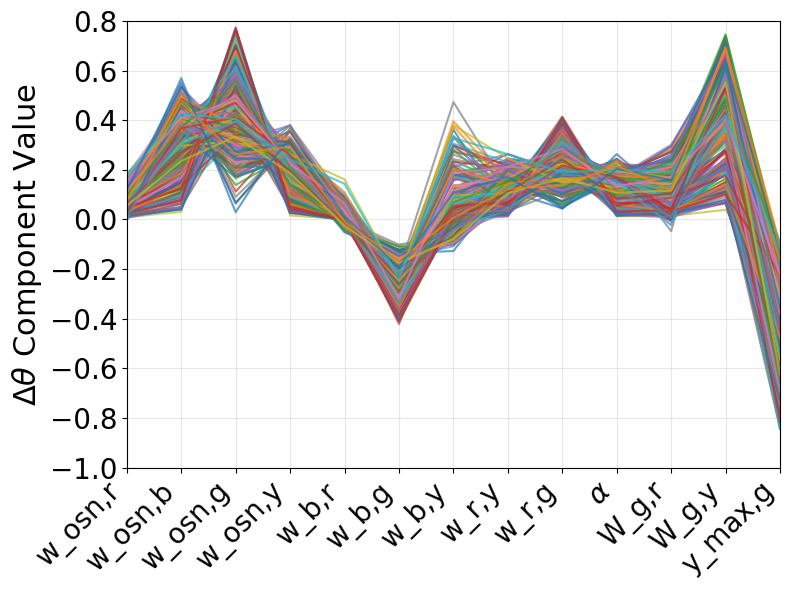

In [185]:
# Vectors with y_max, < -0.1
idx_y_max = param_labels.index('y_max,g')

mask = (x_collect_np[:, idx_y_max] < -0.1)
x_collect_filtered = x_collect_np[mask]
print(f'{x_collect_filtered.shape[0]} / {x_collect_np.shape[0]} vectors match filter')

plt.figure(figsize=(8, 6))
for row_idx in range(x_collect_filtered.shape[0]):
    plt.plot(indices, x_collect_filtered[row_idx], alpha=0.7)


plt.ylabel(r"$\Delta\theta$ Component Value", fontsize=22)
plt.xlim(0, 12)
plt.ylim(-1, 0.8)
plt.xticks(range(len(param_labels)), param_labels, rotation=45, ha='right', fontsize=20)
plt.yticks(fontsize=20)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('Figures_z/x_collect_wbg.eps')
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


ŝ·ĝ (382 filtered, x=1): mean=8.073e-02, std=2.985e-02, min=7.640e-03, max=1.371e-01


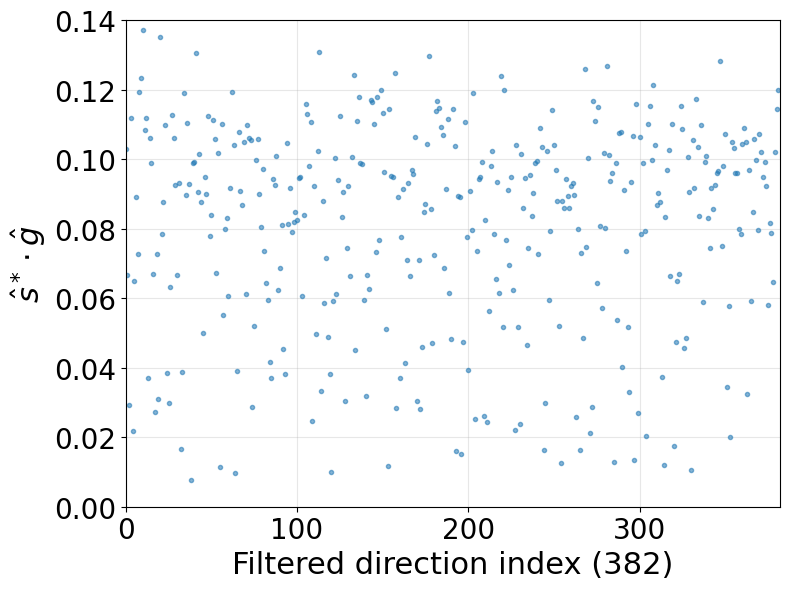

In [211]:
# Gradient dot ŝ*·ĝ vs filtered direction index (each s* is paired with the gradient at its own theta*)
# x_collect rows (section 5) are s_perp* + v for theta_opt[i], and `mask` (y_max,g < -0.1) selects the same rows
# of x_collect_filtered and theta_opt
n_retained = x_collect_filtered.shape[0]
assert n_retained == int(mask.sum())

theta_matched_jax = jnp.asarray(theta_opt[mask])

X_rows = np.asarray(x_collect_filtered)
X_hat_rows = X_rows / np.maximum(np.linalg.norm(X_rows, axis=1, keepdims=True), 1e-30)

def make_batched_grad(x_osn):
    def y_output_sum(theta):
        r, g, b, y = mitral_output(theta, x_osn, m, n_r, n_b, n_g, n_y)
        return jnp.sum(y)
    return jax.jit(jax.vmap(jax.grad(y_output_sum)))

def compute_dots_matched(x_osn):
    G_matched = np.asarray(make_batched_grad(x_osn)(theta_matched_jax))
    G_hat_matched = G_matched / np.maximum(np.linalg.norm(G_matched, axis=1, keepdims=True), 1e-30)
    return np.sum(X_hat_rows * G_hat_matched, axis=1)

# x = 1 operating point the baselines were optimised at (same as the Hessian in section 5)
x_osn = jnp.ones(m)
dir_index = np.arange(n_retained)

dots_matched = compute_dots_matched(x_osn)
print(
    f'ŝ·ĝ ({n_retained} filtered, x=1): '
    f'mean={np.mean(dots_matched):.3e}, std={np.std(dots_matched):.3e}, '
    f'min={dots_matched.min():.3e}, max={dots_matched.max():.3e}'
)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(dir_index, dots_matched, '.', ms=6, alpha=0.55, color='C0')
ax.set_xlabel(rf'Filtered direction index ({n_retained})', fontsize=22)
ax.set_ylabel(r'$\hat{s}^* \cdot \hat{g}$', fontsize=22)
ax.tick_params(axis='both', labelsize=20, direction='out')
ax.grid(True, alpha=0.3)
ax.set_xlim(0, 382)
ax.set_ylim(0, 0.14)
plt.tight_layout()
plt.savefig('Figures_z/x_collect_gradient_dots.eps')
plt.show()


In [187]:
# First- and second-order terms of Δy for a unit step along each filtered ŝ*_i (ε = 1, ||ŝ*|| = 1):
#   Δy ≈ g·ŝ + ½ ŝᵀ H ŝ,  with g, H of y_sum at the matching θ*_i and x = 1
x_term = jnp.ones(m)

def _y_sum_term(theta):
    r, g, b, y = mitral_output(theta, x_term, m, n_r, n_b, n_g, n_y)
    return jnp.sum(y)

_grad_term_fn = jax.jit(jax.grad(_y_sum_term))
_hess_term_fn = jax.jit(jax.jacrev(jax.grad(_y_sum_term)))

S_unit = jnp.asarray(X_hat_rows)                    # unit s*_i for the filtered baselines (cell above)
grad_term = np.zeros(n_retained)                    # g·ŝ
hess_term = np.zeros(n_retained)                    # ½ ŝᵀ H ŝ
for i in range(n_retained):
    if i % 100 == 0:
        print(f"  Direction {i+1}/{n_retained}...")
    theta_i = theta_matched_jax[i]
    s_i = S_unit[i]
    g_i = _grad_term_fn(theta_i)
    H_i = jnp.squeeze(_hess_term_fn(theta_i))
    grad_term[i] = float(g_i @ s_i)
    hess_term[i] = float(0.5 * s_i @ H_i @ s_i)

total_term = grad_term + hess_term
for name, vals in [("g·ŝ", grad_term), ("½ ŝᵀHŝ", hess_term), ("g·ŝ + ½ ŝᵀHŝ", total_term)]:
    print(f"{name}: mean={vals.mean():.3e}, std={vals.std():.3e}, min={vals.min():.3e}, max={vals.max():.3e}")


  Direction 1/382...
  Direction 101/382...
  Direction 201/382...
  Direction 301/382...
g·ŝ: mean=1.140e-01, std=4.356e-02, min=1.046e-02, max=2.081e-01
½ ŝᵀHŝ: mean=4.622e-02, std=2.213e-02, min=4.368e-03, max=9.941e-02
g·ŝ + ½ ŝᵀHŝ: mean=1.603e-01, std=4.856e-02, min=1.483e-02, max=2.267e-01


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


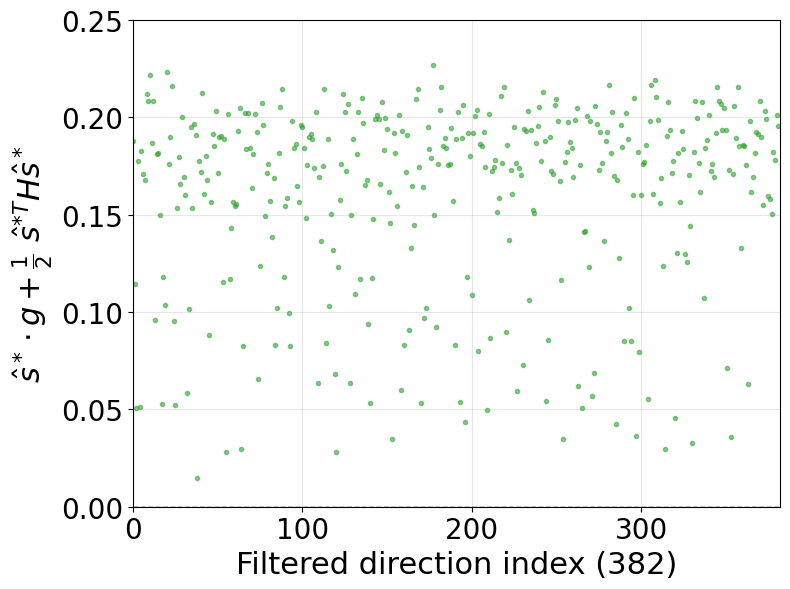

In [212]:
# Gradient term + Hessian term for each filtered direction (in index order)
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(dir_index, total_term, '.', ms=6, alpha=0.55, color='C2')
ax.axhline(0, color='k', lw=1, ls='--')
ax.set_xlabel(rf'Filtered direction index ({n_retained})', fontsize=22)
ax.set_ylabel(r'$\hat{s}^* \cdot g + \frac{1}{2}~\hat{s}^{*T} H \hat{s}^*$', fontsize=22)
ax.tick_params(axis='both', labelsize=20, direction='out')
ax.grid(True, alpha=0.3)
#start at (0,0)
ax.set_xlim(0, 382)
ax.set_ylim(0, 0.25)
plt.tight_layout()
plt.savefig('Figures_z/gradient_plus_hessian_term.eps')
plt.show()


14 / 382 filtered vectors have g·ŝ + ½ ŝᵀHŝ < 0.05


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


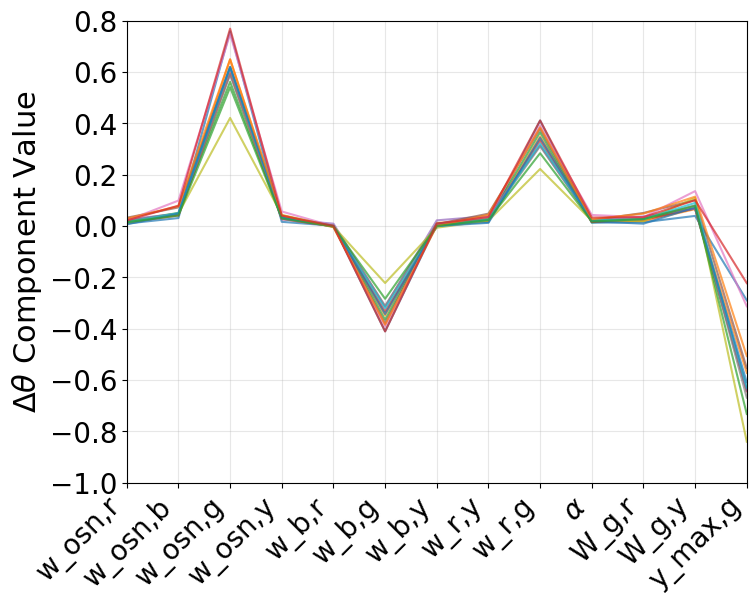

In [213]:
# s* with a small total (g·ŝ + ½ ŝᵀHŝ < 0.05), plotted as in the x_collect plots
total_thresh = 0.05
sel = total_term < total_thresh
x_collect_low = x_collect_filtered[sel]
print(f'{x_collect_low.shape[0]} / {n_retained} filtered vectors have g·ŝ + ½ ŝᵀHŝ < {total_thresh}')

plt.figure(figsize=(8, 6))
for row_idx in range(x_collect_low.shape[0]):
    plt.plot(indices, x_collect_low[row_idx], alpha=0.7)

plt.ylabel(r"$\Delta\theta$ Component Value", fontsize=22)
plt.xlim(0, 12)
plt.ylim(-1, 0.8)
plt.xticks(range(len(param_labels)), param_labels, rotation=45, ha='right', fontsize=20)
plt.yticks(fontsize=20)
plt.grid(True, alpha=0.3)
plt.tight_layout
plt.savefig('Figures_z/x_collect_low_total_term.eps')
plt.show()


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


1 / 382 filtered vectors have g·ŝ + ½ ŝᵀHŝ < 0.02


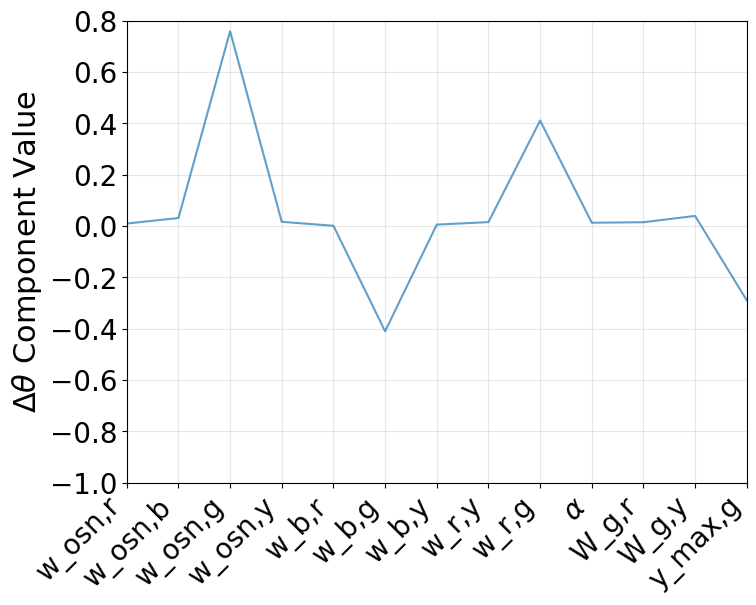

In [195]:
total_thresh = 0.02
sel = total_term < total_thresh
x_collect_lowest = x_collect_filtered[sel]
print(f'{x_collect_lowest.shape[0]} / {n_retained} filtered vectors have g·ŝ + ½ ŝᵀHŝ < {total_thresh}')

plt.figure(figsize=(8, 6))
for row_idx in range(x_collect_lowest.shape[0]):
    plt.plot(indices, x_collect_lowest[row_idx], alpha=0.7)

plt.ylabel(r"$\Delta\theta$ Component Value", fontsize=22)
plt.xlim(0, 12)
plt.ylim(-1, 0.8)
plt.xticks(range(len(param_labels)), param_labels, rotation=45, ha='right', fontsize=20)
plt.yticks(fontsize=20)
plt.grid(True, alpha=0.3)
plt.savefig('Figures_z/x_collect_lowest_total_term.eps')
plt.show()

In [201]:
x_collect_average = x_collect_low.mean(axis=0)
#x_collect_average = x_collect_lowest.mean(axis=0)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


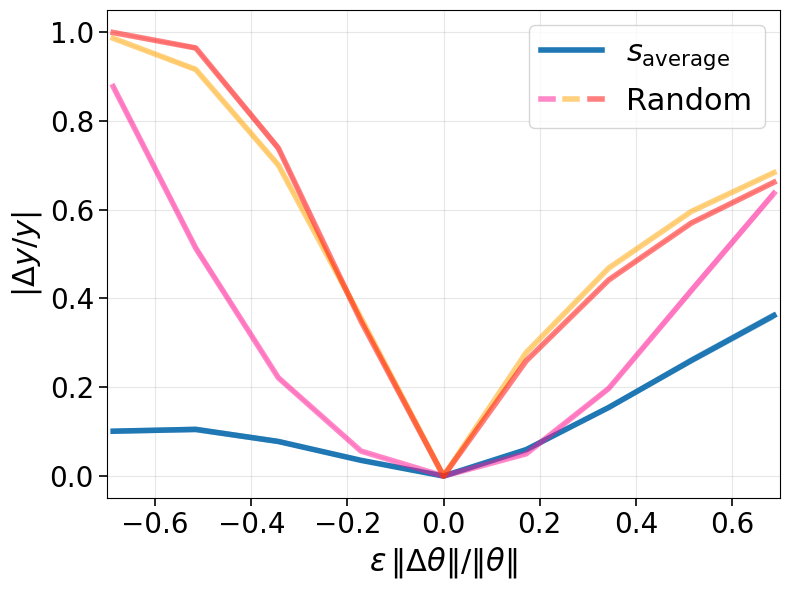

In [207]:
e = np.arange(-2, 2 + 0.2, 0.5)
n_samples = theta_opt.shape[0]

# OSN input: the x = 1 operating point the baselines were optimised at (same as the Hessian / gradient terms above;
# defined locally so it can't be overwritten by other cells)
x_osn = jnp.ones(m)

theta_opt_subset = jnp.array(theta_opt[:n_samples])
key = jax.random.PRNGKey(4)

def _mitral_single(theta):
    return mitral_output(theta, x_osn, m, n_r, n_b, n_g, n_y)

mitral_output_batch = jax.jit(jax.vmap(_mitral_single))

_, _, _, y_baseline = mitral_output_batch(theta_opt_subset)
y_baseline = np.array(y_baseline)

norm_theta_all = np.linalg.norm(theta_opt_subset, axis=1)   # ||theta_0|| for each baseline

# x_collect_average (mean of the low-total s*, cell above) + three random directions
mean_direction = jnp.array(x_collect_average)
mean_direction = mean_direction / jnp.linalg.norm(mean_direction)
n_random = 3

x_directions = [
    (r"$s_{\mathrm{average}}$", mean_direction),
]

# Match x_collect construction: y_max,g component pinned to -1 (the "decrease y_max,g" convention of section 5,
# v = -1), other 12 components random, then normalise
n_params_total = theta_opt_subset.shape[1]

random_directions = []
for _ in range(n_random):
    key, subkey = jax.random.split(key)
    random_dir = jax.random.normal(subkey, (n_params_total,))
    random_dir = random_dir.at[idx_y_max].set(-1.0)
    random_dir = random_dir / jnp.linalg.norm(random_dir)
    random_directions.append(random_dir)


def _lighter_fill_color(color, blend=0.55):
    """Blend matplotlib color toward white for CI shading."""
    import matplotlib.colors as mcolors

    cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    if isinstance(color, str) and color.startswith("C") and color[1:].isdigit():
        rgb = mcolors.to_rgb(cycle[int(color[1:]) % len(cycle)])
    else:
        rgb = mcolors.to_rgb(color)
    return tuple(x + blend * (1.0 - x) for x in rgb)



opt_colors = [f"C{i}" for i in range(len(x_directions))]
random_colors = ["deeppink", "orange", "red"]

directions = [
    (label, direction, opt_colors[i])
    for i, (label, direction) in enumerate(x_directions)
]
for r, direction in enumerate(random_directions):
    directions.append(("_nolegend_", direction, random_colors[r]))


def plot_stepping(ax, direction, color, alpha=1.0):
    y_save = []
    for i in range(len(e)):
        theta_step = theta_opt_subset + e[i] * direction
        _, _, _, y = mitral_output_batch(theta_step)
        y_save.append(np.array(y))
    y_array = np.array(y_save)

    # eps_tilde = eps * ||dtheta|| / ||theta_0||, with ||theta_0|| of each baseline (n_eps, n_samples)
    theta_ratio_all = e[:, None] * np.linalg.norm(direction) / norm_theta_all[None, :]
    # the CI is taken over baselines at each eps, so plot each eps at the mean eps_tilde over baselines
    theta_ratio = theta_ratio_all.mean(axis=1)
    y0_baseline = y_baseline[:, 0]
    rel0 = np.where(
        np.abs(y0_baseline) > 1e-12,
        (y_array[:, :, 0] - y0_baseline) / y0_baseline,
        y_array[:, :, 0] - y0_baseline,
    )
    abs_rel0 = np.abs(rel0)
    theta_ratio_expanded = np.repeat(theta_ratio, n_samples)
    fill_color = _lighter_fill_color(color)

    sns.lineplot(
        x=theta_ratio_expanded,
        y=abs_rel0.ravel(),
        ax=ax,
        color=color,
        errorbar=("ci", 95),
        legend=False,
        linewidth=0,
        err_kws={
            "facecolor": fill_color,
            "edgecolor": "none",
            "alpha": 0.65 * alpha,
        },
    )
    sns.lineplot(
        x=theta_ratio_expanded,
        y=abs_rel0.ravel(),
        ax=ax,
        color=color,
        errorbar=None,
        legend=False,
        linewidth=4,
        alpha=alpha,
    )


fig, ax = plt.subplots(figsize=(8, 6))

for label, direction, color in directions:
    plot_stepping(
        ax,
        direction,
        color,
        alpha=0.5 if label == "_nolegend_" else 1.0,
    )

ax.set_xlim(-0.7, 0.7)
ax.set_xticks(np.arange(-0.6, 0.61, 0.2))
ax.set_xlabel(
    r"$\epsilon \, \|\Delta \theta\| / \|\theta\|$",
    fontsize=22,
    fontweight="bold",
)
ax.set_ylabel(r"$|\Delta y / y|$", fontsize=22, fontweight="bold")
ax.grid(True, alpha=0.3)
ax.tick_params(
    axis="both",
    which="major",
    direction="out",
    top=False,
    right=False,
    bottom=True,
    left=True,
    labelsize=20,
    width=1.2,
    length=6,
)

opt_handles = [Line2D([0], [0], color=c, lw=4) for c in opt_colors]
random_handles = tuple(
    Line2D([0], [0], color=c, lw=4, alpha=0.5) for c in random_colors
)
opt_labels = [label for label, _, _ in directions if label != "_nolegend_"]
ax.legend(
    handles=opt_handles + [random_handles],
    labels=opt_labels + ["Random"],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    fontsize=22,
    loc="upper right",
)


plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.tight_layout()
plt.savefig("Figures_z/step_in_x_star.eps")
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


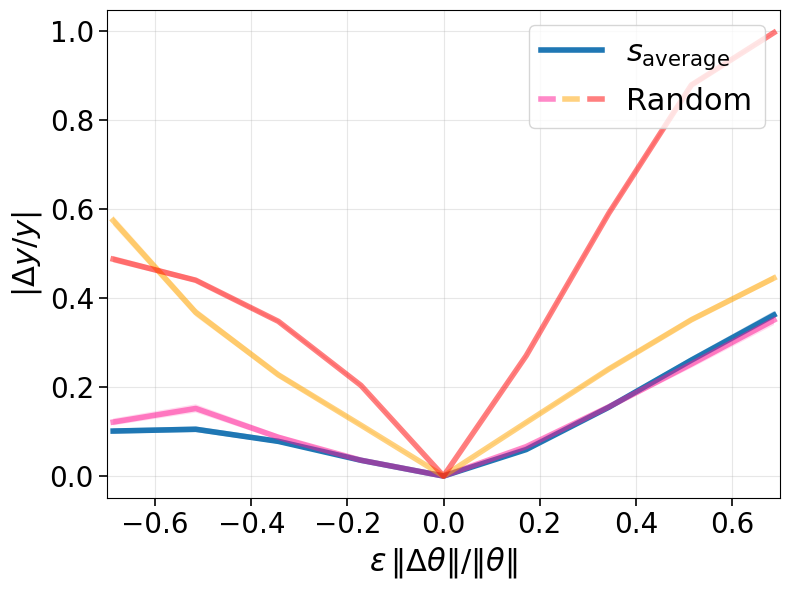

In [206]:
e = np.arange(-2, 2 + 0.2, 0.5)
n_samples = theta_opt.shape[0]

# OSN input: the x = 1 operating point the baselines were optimised at (same as the Hessian / gradient terms above;
# defined locally so it can't be overwritten by other cells)
x_osn = jnp.ones(m)

theta_opt_subset = jnp.array(theta_opt[:n_samples])
key = jax.random.PRNGKey(40)

def _mitral_single(theta):
    return mitral_output(theta, x_osn, m, n_r, n_b, n_g, n_y)

mitral_output_batch = jax.jit(jax.vmap(_mitral_single))

_, _, _, y_baseline = mitral_output_batch(theta_opt_subset)
y_baseline = np.array(y_baseline)

norm_theta_all = np.linalg.norm(theta_opt_subset, axis=1)   # ||theta_0|| for each baseline

# x_collect_average (mean of the low-total s*, cell above) + three random directions
mean_direction = jnp.array(x_collect_average)
mean_direction = mean_direction / jnp.linalg.norm(mean_direction)
n_random = 3

x_directions = [
    (r"$s_{\mathrm{average}}$", mean_direction),
]

# Match x_collect construction: y_max,g component pinned to -1 (the "decrease y_max,g" convention of section 5,
# v = -1), other 12 components random, then normalise
n_params_total = theta_opt_subset.shape[1]

random_directions = []
for _ in range(n_random):
    key, subkey = jax.random.split(key)
    random_dir = jax.random.normal(subkey, (n_params_total,))
    random_dir = random_dir.at[idx_y_max].set(-1.0)
    random_dir = random_dir / jnp.linalg.norm(random_dir)
    random_directions.append(random_dir)


def _lighter_fill_color(color, blend=0.55):
    """Blend matplotlib color toward white for CI shading."""
    import matplotlib.colors as mcolors

    cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    if isinstance(color, str) and color.startswith("C") and color[1:].isdigit():
        rgb = mcolors.to_rgb(cycle[int(color[1:]) % len(cycle)])
    else:
        rgb = mcolors.to_rgb(color)
    return tuple(x + blend * (1.0 - x) for x in rgb)



opt_colors = [f"C{i}" for i in range(len(x_directions))]
random_colors = ["deeppink", "orange", "red"]

directions = [
    (label, direction, opt_colors[i])
    for i, (label, direction) in enumerate(x_directions)
]
for r, direction in enumerate(random_directions):
    directions.append(("_nolegend_", direction, random_colors[r]))


def plot_stepping(ax, direction, color, alpha=1.0):
    y_save = []
    for i in range(len(e)):
        theta_step = theta_opt_subset + e[i] * direction
        _, _, _, y = mitral_output_batch(theta_step)
        y_save.append(np.array(y))
    y_array = np.array(y_save)

    # eps_tilde = eps * ||dtheta|| / ||theta_0||, with ||theta_0|| of each baseline (n_eps, n_samples)
    theta_ratio_all = e[:, None] * np.linalg.norm(direction) / norm_theta_all[None, :]
    # the CI is taken over baselines at each eps, so plot each eps at the mean eps_tilde over baselines
    theta_ratio = theta_ratio_all.mean(axis=1)
    y0_baseline = y_baseline[:, 0]
    rel0 = np.where(
        np.abs(y0_baseline) > 1e-12,
        (y_array[:, :, 0] - y0_baseline) / y0_baseline,
        y_array[:, :, 0] - y0_baseline,
    )
    abs_rel0 = np.abs(rel0)
    theta_ratio_expanded = np.repeat(theta_ratio, n_samples)
    fill_color = _lighter_fill_color(color)

    sns.lineplot(
        x=theta_ratio_expanded,
        y=abs_rel0.ravel(),
        ax=ax,
        color=color,
        errorbar=("ci", 95),
        legend=False,
        linewidth=0,
        err_kws={
            "facecolor": fill_color,
            "edgecolor": "none",
            "alpha": 0.65 * alpha,
        },
    )
    sns.lineplot(
        x=theta_ratio_expanded,
        y=abs_rel0.ravel(),
        ax=ax,
        color=color,
        errorbar=None,
        legend=False,
        linewidth=4,
        alpha=alpha,
    )


fig, ax = plt.subplots(figsize=(8, 6))

for label, direction, color in directions:
    plot_stepping(
        ax,
        direction,
        color,
        alpha=0.5 if label == "_nolegend_" else 1.0,
    )

ax.set_xlim(-0.7, 0.7)
ax.set_xticks(np.arange(-0.6, 0.61, 0.2))
ax.set_xlabel(
    r"$\epsilon \, \|\Delta \theta\| / \|\theta\|$",
    fontsize=22,
    fontweight="bold",
)
ax.set_ylabel(r"$|\Delta y / y|$", fontsize=22, fontweight="bold")
ax.grid(True, alpha=0.3)
ax.tick_params(
    axis="both",
    which="major",
    direction="out",
    top=False,
    right=False,
    bottom=True,
    left=True,
    labelsize=20,
    width=1.2,
    length=6,
)

opt_handles = [Line2D([0], [0], color=c, lw=4) for c in opt_colors]
random_handles = tuple(
    Line2D([0], [0], color=c, lw=4, alpha=0.5) for c in random_colors
)
opt_labels = [label for label, _, _ in directions if label != "_nolegend_"]
ax.legend(
    handles=opt_handles + [random_handles],
    labels=opt_labels + ["Random"],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    fontsize=22,
    loc="upper right",
)


plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.tight_layout()
plt.savefig("Figures_z/step_in_x_star.eps")
plt.show()